In [17]:
import torch
import matplotlib.pyplot as plt
from ddpm.masks.rad_masks import(box, channel_strip, time_strip, oriented_band, anisotropic_perlin, random_rad_mask)

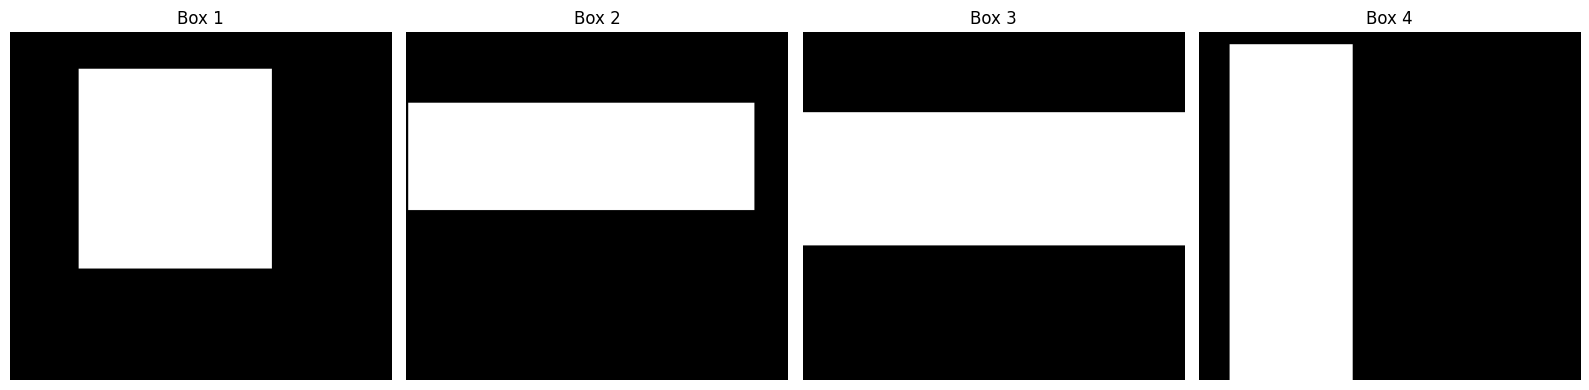

In [94]:
device = "cuda" if torch.cuda.is_available() else "cpu"
B=4
H=256
W=512
masks = box(B=B, H=H, W=W, device= device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Box {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

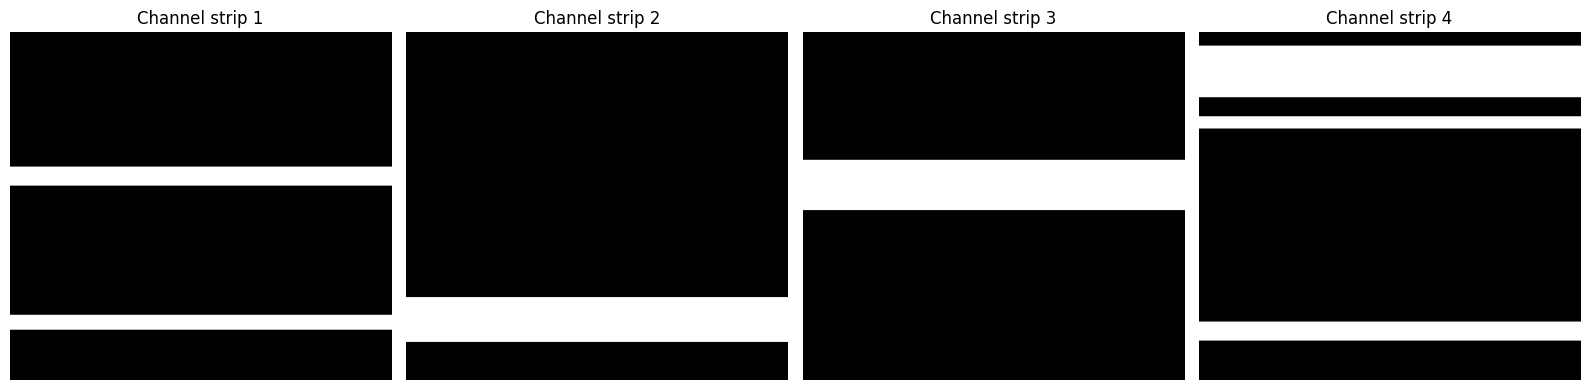

In [95]:
masks = channel_strip(B, H, W, device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Channel strip {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

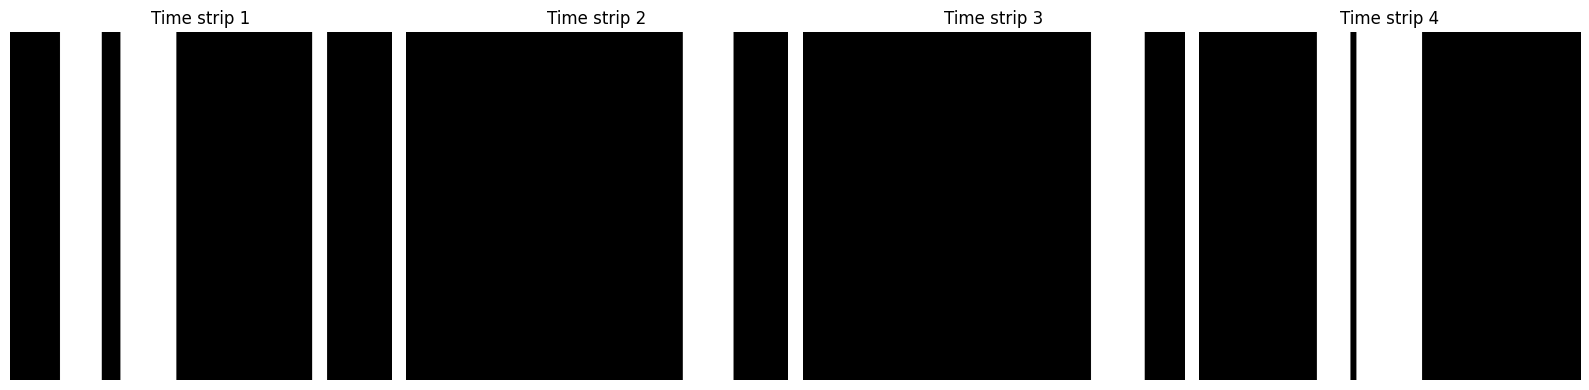

In [96]:
masks = time_strip(B, H, W, device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Time strip {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

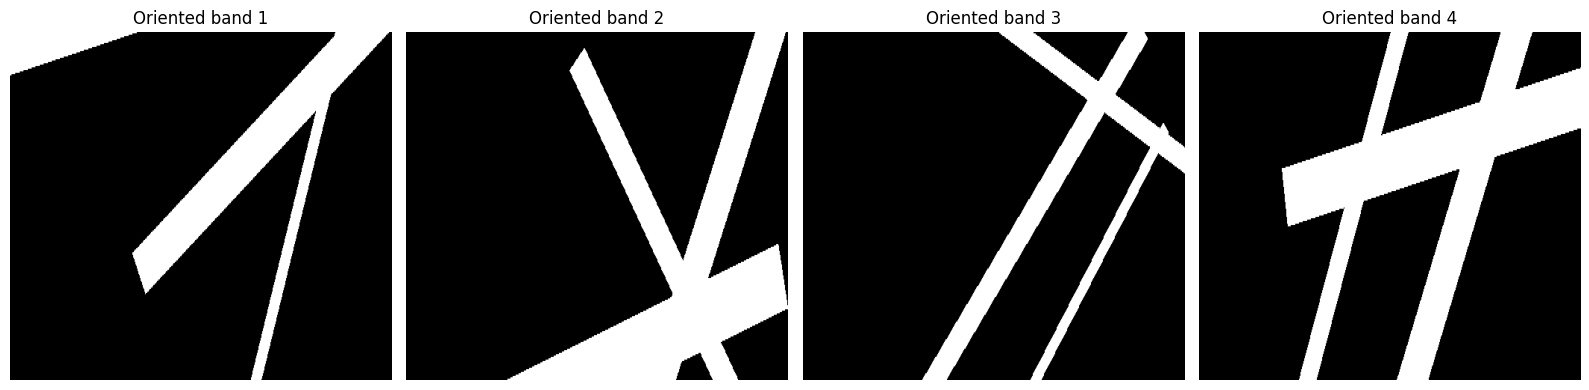

In [102]:
masks = oriented_band(B, H, W,thickness_range=(0.04,0.20), length_range=(0.60, 1.40), count_range=(1,3), device=device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Oriented band {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [87]:
import importlib
from ddpm.masks import rad_masks as masks
importlib.reload(masks)

<module 'ddpm.masks.rad_masks' from '/home/islem.dhouioui/ddpm/src/ddpm/masks/rad_masks.py'>

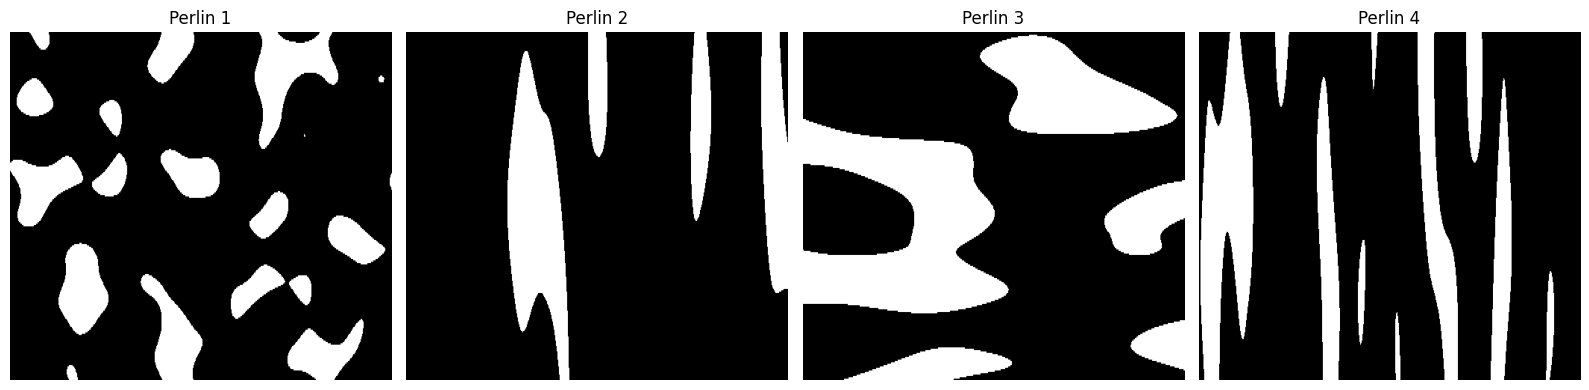

In [103]:
masks = anisotropic_perlin(B, H, W, device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Perlin {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [29]:
from pathlib import Path
from torch.utils.data import DataLoader
from ddpm.data.das_dataset import DasDataset

In [30]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_earthquake = [das_data/"train_1001.h5"]
test_files_earthquake = [das_data/"test_1001.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_earthquake = DasDataset(train_files_earthquake)
test_set_earthquake = DasDataset(test_files_earthquake)
train_loader_earthquake = DataLoader(train_set_earthquake, batch_size=16, shuffle=True)
test_loader_earthquake = DataLoader(test_set_earthquake, batch_size=16, shuffle=False)

In [88]:
batch = next(iter(train_loader_earthquake))
x = batch.to(device)

B_vis = 4
x = x[:B_vis]

B, C, H, W = x.shape

masks = random_rad_mask(B=B, H=H, W=W, device=device)
masked_x = x*(1 - masks)

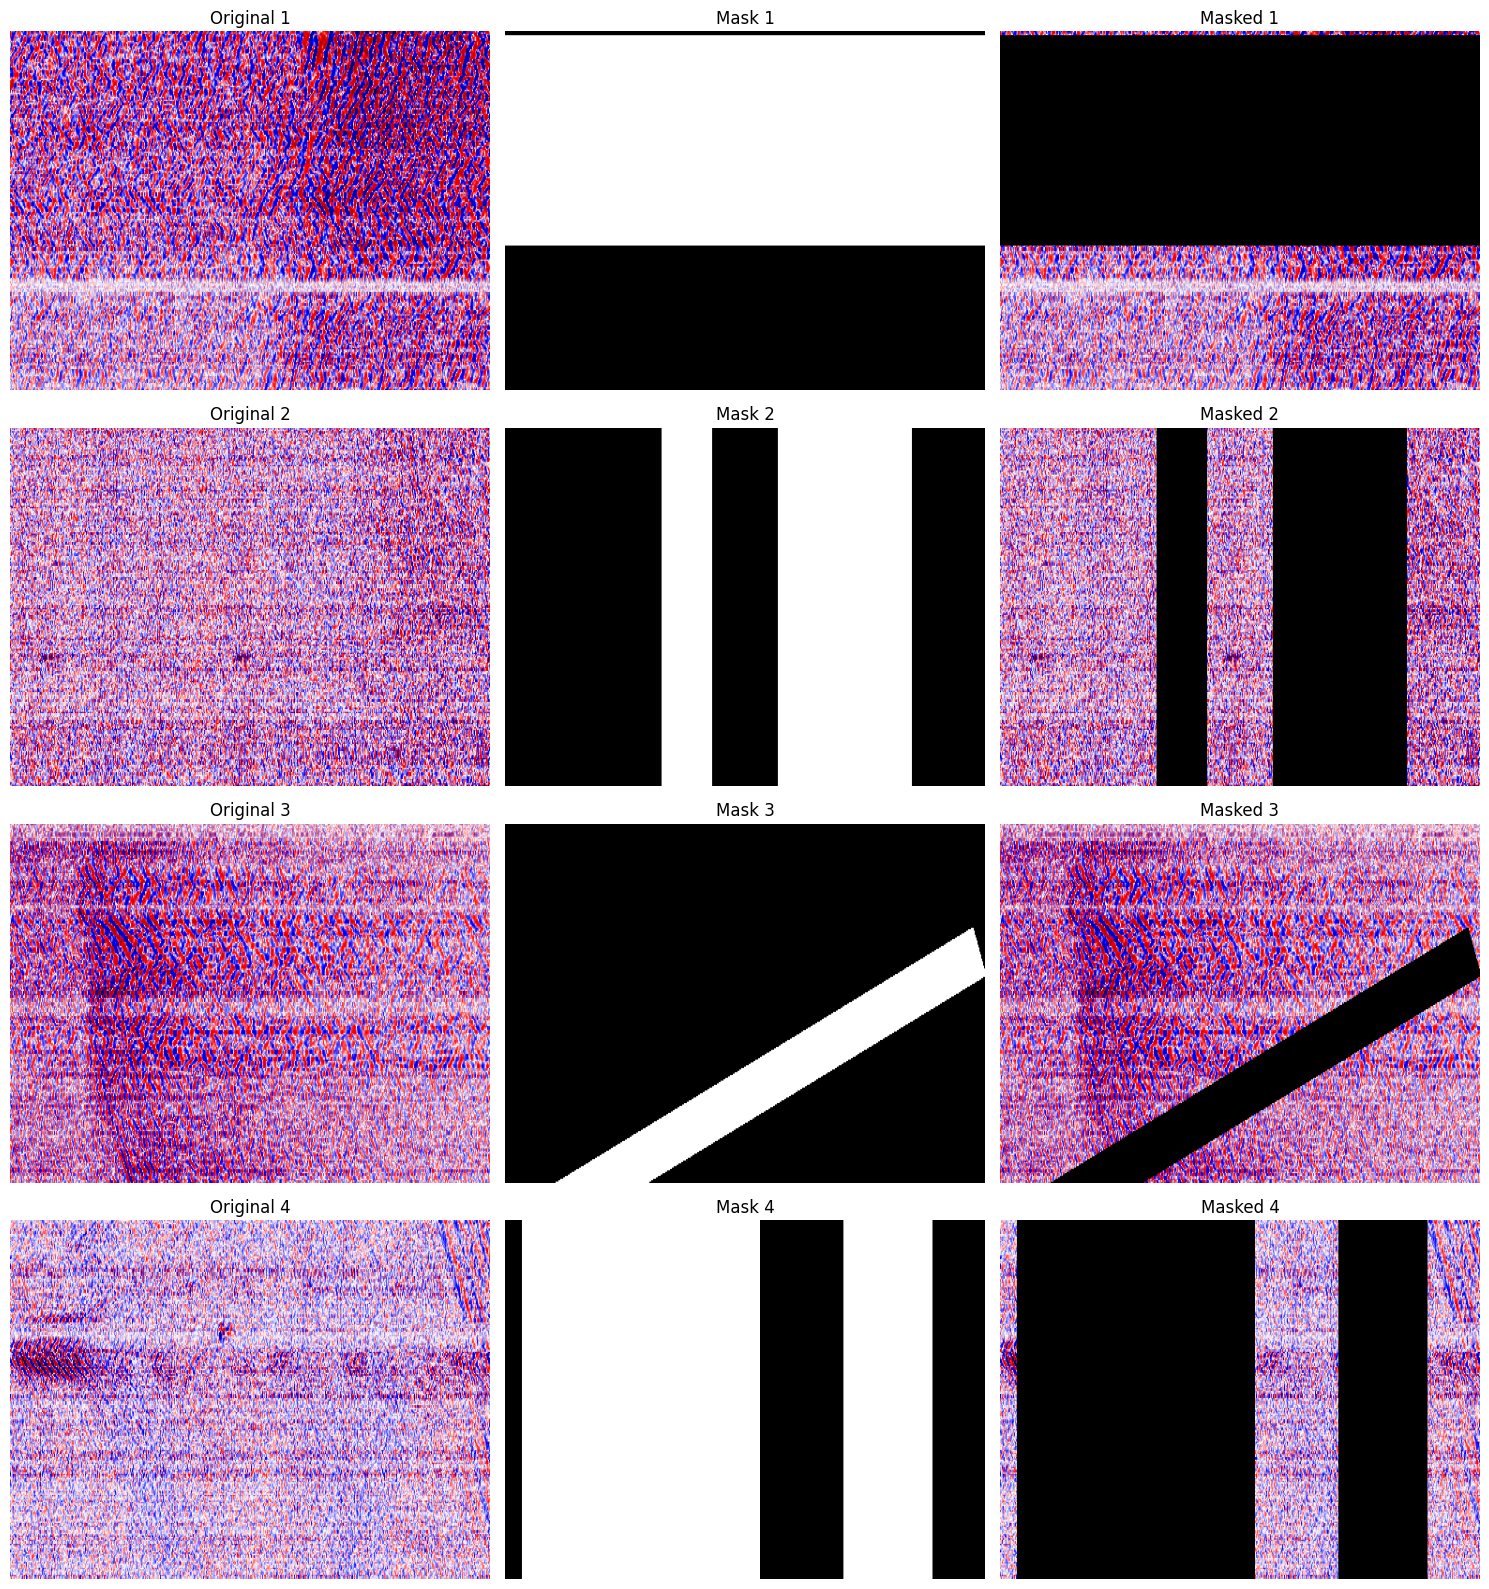

In [89]:
from matplotlib.colors import ListedColormap

black_mask = ListedColormap([(0, 0, 0, 0), (0, 0, 0, 1)])

fig, axes = plt.subplots(B_vis, 3, figsize=(15, 4 * B_vis))

for i in range(B_vis):
    axes[i, 0].imshow(x[i, 0].cpu(), aspect="auto", cmap="seismic")
    axes[i, 0].set_title(f"Original {i+1}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i, 1].set_title(f"Mask {i+1}")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(x[i, 0].cpu(), aspect="auto", cmap="seismic")
    axes[i, 2].imshow(masks[i, 0].cpu(), aspect="auto", cmap=black_mask)
    axes[i, 2].set_title(f"Masked {i+1}")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [90]:
area_fraction = masks.mean(dim=(1, 2, 3)).cpu()
print(area_fraction.tolist())

[0.5859375, 0.384765625, 0.124908447265625, 0.681640625]


In [ ]:
fractions = []

for _ in range(200):
    masks = random_rad_mask(B=16,H=256,W=512,device=device)
    fractions.extend(masks.mean(dim=(1, 2, 3)).cpu().tolist())

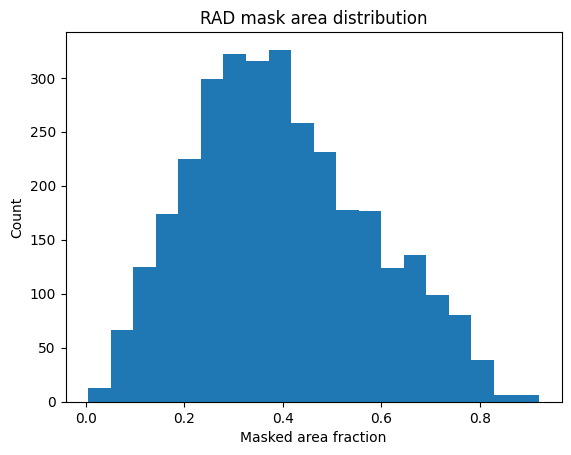

In [92]:
plt.hist(fractions, bins=20)
plt.xlabel("Masked area fraction")
plt.ylabel("Count")
plt.title("RAD mask area distribution")
plt.show()

In [79]:
print("min:", min(fractions))
print("max:", max(fractions))
print("mean:", sum(fractions) / len(fractions))

min: 0.0048828125
max: 0.884765625
mean: 0.364073314666748
